# 01 · Exploratory data analysis: SPY vs QQQ

**Goal:** understand the data before modelling, and test the assumptions the Monte Carlo and A/B
test rely on. Data comes **live from PostgreSQL** (loaded from the yfinance and Alpha Vantage APIs
by `python -m etf_pipeline run`). No CSV files are involved.

Questions:
1. Is the data complete and clean?
2. How have SPY and QQQ performed, year by year?
3. Are daily returns normal? (The GBM model assumes they are.)
4. Do volatility shocks cluster? (This motivates the block bootstrap and the ML volatility model.)
5. Is the SPY–QQQ correlation stable? (The Monte Carlo uses one correlation.)
6. What did the worst drawdowns look like?

In [1]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))   # run from notebooks/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from etf_pipeline import db

plt.rcParams.update({"figure.figsize": (11, 4), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linestyle": "-"})
COLORS = {"SPY": "#2a78d6", "QQQ": "#eb6834", "DIA": "#1baf7a", "IWM": "#eda100", "VTI": "#e87ba4"}

prices = db.read_sql("""
    SELECT a.symbol, a.asset_class, p.trade_date, p.close::float AS close, p.adj_close::float AS adj_close, p.volume
    FROM price_daily p JOIN asset a USING (asset_id) ORDER BY a.symbol, p.trade_date""", parse_dates=["trade_date"])
rf = db.read_sql("SELECT rate_date, annual_rate::float AS annual_rate FROM risk_free_rate ORDER BY rate_date", parse_dates=["rate_date"])
prices.groupby("symbol").agg(first=("trade_date", "min"), last=("trade_date", "max"), rows=("trade_date", "size"))

,first,last,rows
symbol,,,
DIA,1999-03-10,2026-10-13,6942
IWM,2000-05-26,2026-10-13,6634
QQQ,1999-03-10,2026-10-13,6942
SPY,1999-03-10,2026-10-13,6942
VTI,2001-06-15,2026-10-13,6369
^VIX,1999-03-10,2026-10-13,6944


## 1. Data quality

In [2]:
etf = prices[prices.asset_class == "ETF"]
wide = etf.pivot(index="trade_date", columns="symbol", values="adj_close")
checks = pd.DataFrame({
    "missing_after_start": wide.apply(lambda s: s.loc[s.first_valid_index():].isna().sum()),
    "non_positive": (wide <= 0).sum(),
    "duplicate_dates": etf.duplicated(["symbol", "trade_date"]).groupby(etf.symbol).sum(),
})
gaps = wide.index.to_series().diff().dt.days
print("Longest calendar gap between trading days:", gaps.max(), "days on", gaps.idxmax().date())
checks

Longest calendar gap between trading days: 7.0 days on 2001-09-17


,missing_after_start,non_positive,duplicate_dates
symbol,,,
DIA,0,0,0
IWM,0,0,0
QQQ,0,0,0
SPY,0,0,0
VTI,0,0,0


In [3]:
# Largest single-day moves: real events, or data errors?
rets = wide[["SPY", "QQQ"]].pct_change()
extremes = pd.concat({s: rets[s].abs().nlargest(5) for s in ["SPY", "QQQ"]}).rename("abs_return").reset_index()
extremes.columns = ["symbol", "date", "abs_daily_return"]
extremes

,symbol,date,abs_daily_return
0,SPY,2008-10-13,0.145199
1,SPY,2008-10-28,0.116856
2,SPY,2020-03-16,0.109424
3,SPY,2025-04-09,0.105019
4,SPY,2008-10-15,0.098448
5,QQQ,2001-01-03,0.168423
6,QQQ,2000-01-07,0.123684
7,QQQ,2008-10-13,0.121649
8,QQQ,2025-04-09,0.120031
9,QQQ,2020-03-16,0.119788


The extreme days line up with known market events (2000–02 dot-com crash, Oct 2008, Mar 2020),
so they are real moves, not data errors. They stay in the data.

## 2. Performance over time

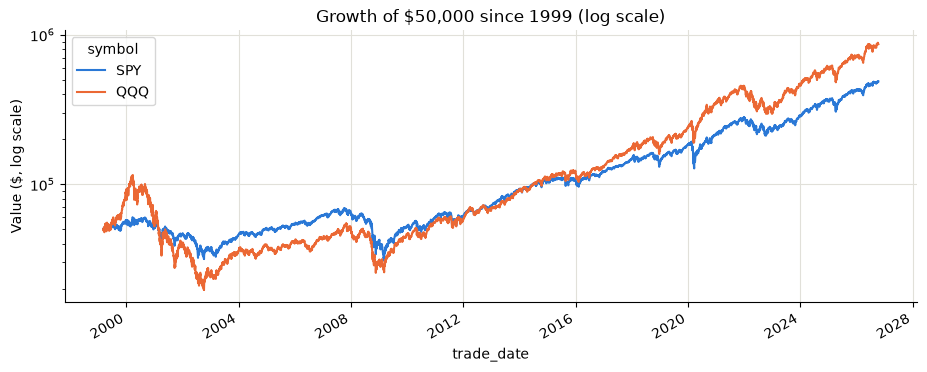

In [4]:
core = wide[["SPY", "QQQ"]].dropna()
growth = 50_000 * core / core.iloc[0]
ax = growth.plot(color=[COLORS[c] for c in growth], logy=True, title="Growth of $50,000 since 1999 (log scale)")
ax.set_ylabel("Value ($, log scale)");

In [5]:
annual = core.resample("YE").last().pct_change().dropna()
annual.index = annual.index.year
annual["QQQ − SPY"] = annual["QQQ"] - annual["SPY"]
print(f"QQQ beat SPY in {(annual['QQQ − SPY'] > 0).sum()} of {len(annual)} calendar years")
annual.style.format("{:.1%}").background_gradient(subset=["QQQ − SPY"], cmap="RdBu", vmin=-0.4, vmax=0.4)

QQQ beat SPY in 17 of 27 calendar years


symbol,SPY,QQQ,QQQ − SPY
trade_date,,,
2000,-9.7%,-36.1%,-26.4%
2001,-11.8%,-33.3%,-21.6%
2002,-21.6%,-37.4%,-15.8%
2003,28.2%,49.7%,21.5%
2004,10.7%,10.5%,-0.2%
2005,4.8%,1.6%,-3.3%
2006,15.8%,7.1%,-8.7%
2007,5.1%,19.0%,13.9%
2008,-36.8%,-41.7%,-4.9%


## 3. Are daily returns normal?

In [6]:
lr = np.log(core).diff().dropna()
summary = pd.DataFrame({
    "mean (ann.)": lr.mean() * 252, "vol (ann.)": lr.std() * np.sqrt(252),
    "skew": lr.skew(), "excess kurtosis": lr.kurt(),
    "Jarque-Bera p": [stats.jarque_bera(lr[c]).pvalue for c in lr],
    "days beyond 4σ": [(np.abs((lr[c] - lr[c].mean()) / lr[c].std()) > 4).sum() for c in lr],
    "expected if normal": [round(len(lr) * 2 * stats.norm.sf(4), 2)] * 2,
})
summary.round(4)

,mean (ann.),vol (ann.),skew,excess kurtosis,Jarque-Bera p,days beyond 4σ,expected if normal
symbol,,,,,,,
SPY,0.0826,0.1919,-0.2052,11.3833,0.0,43,0.44
QQQ,0.1035,0.2684,0.0045,6.5846,0.0,46,0.44


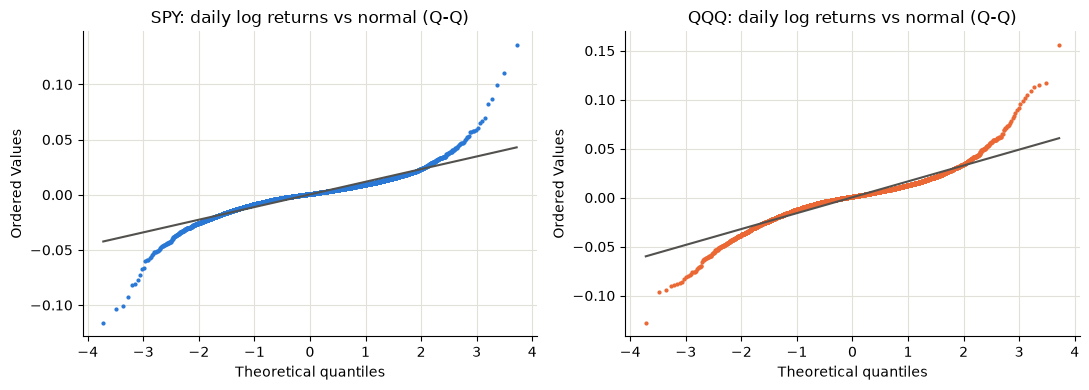

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, s in zip(axes, ["SPY", "QQQ"]):
    stats.probplot(lr[s], dist="norm", plot=ax)
    ax.get_lines()[0].set(markersize=2, color=COLORS[s]); ax.get_lines()[1].set(color="#52514e")
    ax.set_title(f"{s}: daily log returns vs normal (Q-Q)")
plt.tight_layout()

**Finding:** returns are strongly fat-tailed. Excess kurtosis is far above 0, Jarque-Bera
rejects normality, and there are many more 4σ days than a normal distribution allows. **Implication
for the model:** GBM is a reasonable model for central outcomes, but it *understates tail risk*. We
mitigate this by (a) calibrating on the full 1999+ history including three crashes, (b) reporting
the 95th-percentile drawdown alongside VaR, and (c) testing the A/B hypothesis with a
bootstrap of *real* returns rather than a normal model.

## 4. Volatility clustering

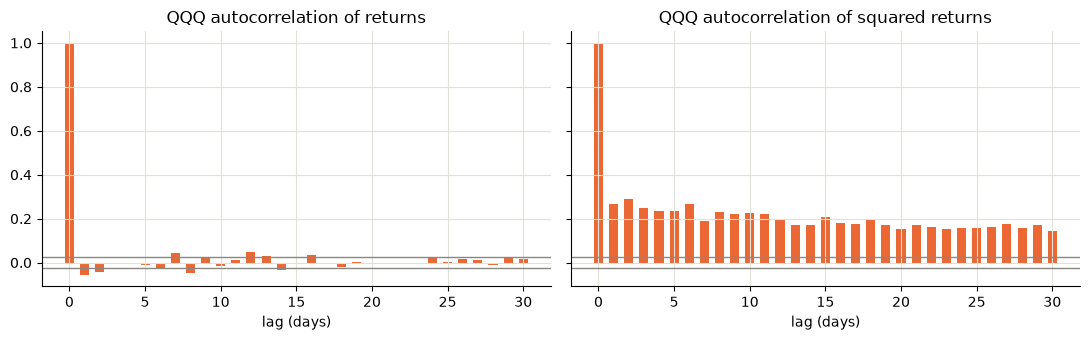

In [8]:
def acf(x, lags=30):
    x = x - x.mean()
    return np.array([1.0] + [np.corrcoef(x[:-k], x[k:])[0, 1] for k in range(1, lags + 1)])

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
for ax, (label, series) in zip(axes, [("returns", lr["QQQ"]), ("squared returns", lr["QQQ"] ** 2)]):
    ax.bar(range(31), acf(series.to_numpy()), color=COLORS["QQQ"], width=0.6)
    ax.axhline(1.96 / np.sqrt(len(series)), color="#898781", lw=1); ax.axhline(-1.96 / np.sqrt(len(series)), color="#898781", lw=1)
    ax.set_title(f"QQQ autocorrelation of {label}"); ax.set_xlabel("lag (days)")
plt.tight_layout()

**Finding:** returns themselves are nearly uncorrelated day to day, but *squared* returns are
strongly autocorrelated for weeks: calm and turbulent periods cluster. **Implications:** (1) the A/B
bootstrap resamples **blocks** of 21 days, not single days, to preserve clustering; (2) next-month
volatility is predictable from recent volatility, which is the basis of the HAR + gradient-boosting
model.

## 5. Is the SPY–QQQ correlation stable?

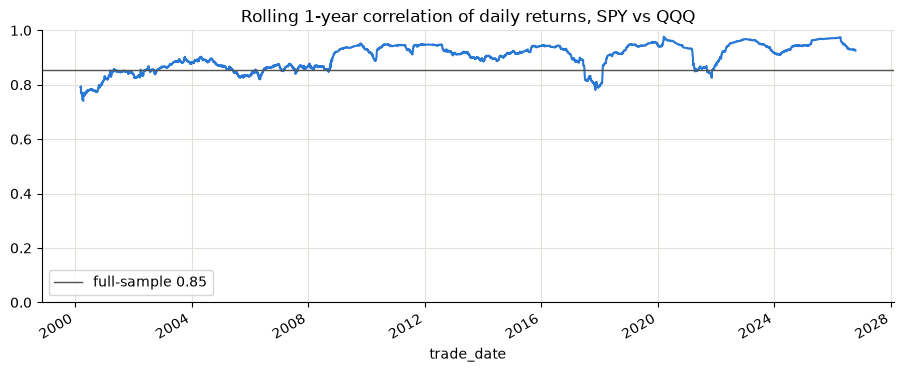

In [9]:
roll_corr = lr["SPY"].rolling(252).corr(lr["QQQ"])
ax = roll_corr.plot(color="#2a78d6", title="Rolling 1-year correlation of daily returns, SPY vs QQQ")
ax.axhline(lr.corr().iloc[0, 1], color="#52514e", lw=1, label=f"full-sample {lr.corr().iloc[0, 1]:.2f}")
ax.legend(); ax.set_ylim(0, 1);

**Finding:** correlation is high and has *risen* over time, as large-cap tech grew to dominate the
S&P 500 too. Diversification between SPY and QQQ is limited, which is why the Sharpe curve across
QQQ shares is so flat and why tail risk, not Sharpe, is the main trade-off.

## 6. Worst drawdowns

In [10]:
def top_drawdowns(px, n=5):
    dd = px / px.cummax() - 1
    out, used = [], pd.Series(False, index=px.index)
    for _ in range(n):
        trough = dd[~used].idxmin()
        peak = px.loc[:trough].idxmax()
        rec = px.loc[trough:][px.loc[trough:] >= px.loc[peak]].first_valid_index()
        out.append({"peak": peak.date(), "trough": trough.date(), "drawdown": dd[trough],
                    "recovered": rec.date() if rec is not None else "not yet",
                    "months to recover": round((rec - trough).days / 30.4) if rec is not None else None})
        used.loc[peak:(rec or px.index[-1])] = True
    return pd.DataFrame(out)

for s in ["QQQ", "SPY"]:
    print(s); display(top_drawdowns(core[s]).style.format({"drawdown": "{:.1%}"}))

QQQ


,peak,trough,drawdown,recovered,months to recover
0,2000-03-27,2002-10-09,-83.0%,2015-02-20,149
1,2021-12-27,2022-11-03,-35.1%,2023-12-13,13
2,2020-02-19,2020-03-16,-28.6%,2020-06-03,3
3,2018-08-29,2018-12-24,-22.8%,2019-04-12,4
4,2025-02-19,2025-04-08,-22.8%,2025-06-24,3


SPY


,peak,trough,drawdown,recovered,months to recover
0,2007-10-09,2009-03-09,-55.2%,2012-08-16,41
1,2000-03-24,2002-10-09,-47.5%,2006-10-26,49
2,2020-02-19,2020-03-23,-33.7%,2020-08-10,5
3,2022-01-03,2022-10-12,-24.5%,2023-12-13,14
4,2018-09-20,2018-12-24,-19.3%,2019-04-12,4


## 7. Risk-free rate

Latest: 4.23% on 2026-10-08


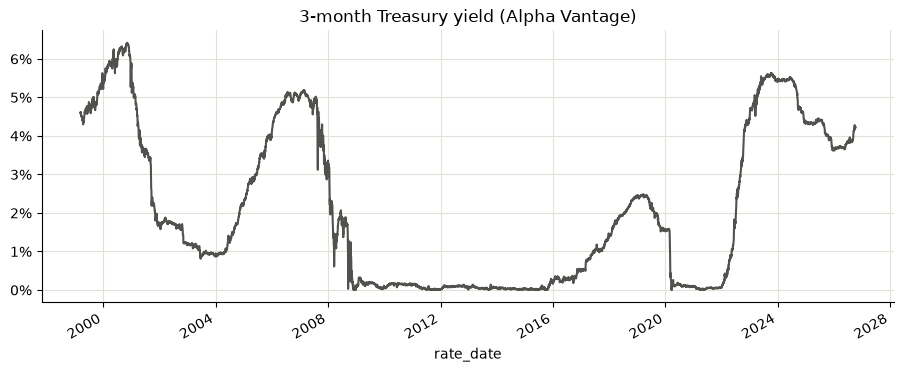

In [11]:
ax = rf.set_index("rate_date")["annual_rate"].plot(color="#52514e", title="3-month Treasury yield (Alpha Vantage)")
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"));
print(f"Latest: {rf.annual_rate.iloc[-1]:.2%} on {rf.rate_date.iloc[-1].date()}")

## Summary → modelling decisions

| EDA finding | Decision |
|---|---|
| Clean data, no gaps beyond market holidays; extreme days are real events | Keep all observations; no outlier removal |
| QQQ's edge varies a lot by period (dot-com bust vs 2010s) | Calibrate the base case on the **full** 1999+ history; run 5/10/15-year sensitivity scenarios |
| Fat tails (kurtosis ≫ 0) | Report drawdown percentiles, not just VaR; bootstrap real returns for the A/B test |
| Volatility clusters | Block bootstrap (21-day blocks); ML volatility forecast; HAC-corrected t-test |
| High and rising SPY–QQQ correlation | Expect a flat Sharpe frontier; frame the decision around tail risk and tolerance |